# 04 - Chemistry, structure and flexibility

The visual layer: 2D chemical structures, 3D poses, and an elastic network model of
protein flexibility.

The elastic network model is the interesting one. It is a physics model with no
knowledge of AlphaFold: springs between nearby alpha-carbons, diagonalised to give
normal modes. If it independently flags the Met20 loop as the mobile region, that is
three separate lines of evidence agreeing - pLDDT, PAE, and now mechanics.

Run notebooks 01-03 first. Kernel: **Python (dhfr)**.

In [1]:
import sys

sys.path.insert(0, "../scripts")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from rdkit import Chem
from rdkit.Chem import AllChem, Draw
from rdkit.Chem.Draw import rdMolDraw2D

import dhfr_lib as D

MET20_LOOP = (9, 24)
FG_LOOP = (116, 132)
GH_LOOP = (142, 150)
ASP27 = 27

TEAL, AMBER, GREY, RED = "#0f4c5c", "#d97a2b", "#8a8a8a", "#b23a2e"

## The molecules

### The reaction DHFR catalyses

DHFR transfers a hydride from the nicotinamide ring of NADPH to C6 of the pterin ring,
with protonation at N5:

$$
\underbrace{\text{7,8-dihydrofolate}}_{\text{DHF}} \;+\; \text{NADPH} \;+\; \mathrm{H}^{+}
\;\xrightarrow{\;\text{DHFR}\;}\;
\underbrace{\text{5,6,7,8-tetrahydrofolate}}_{\text{THF}} \;+\; \text{NADP}^{+}
$$

THF carries one-carbon units for thymidylate and purine synthesis. Each thymidylate made
spends a THF and returns a DHF, so the cycle must keep turning:

$$
\text{THF} \;\xrightarrow{\;\text{dTMP synthesis}\;} \text{DHF} \;\xrightarrow{\;\text{DHFR}\;} \text{THF}
$$

Block DHFR and the THF pool drains, DNA synthesis stalls, and a dividing bacterium stops
growing.

### Competitive inhibition

Trimethoprim competes with DHF for the folate site, so in the steady state

$$
v \;=\; \frac{V_{\max}\,[S]}{K_m\!\left(1 + \dfrac{[I]}{K_i}\right) + [S]}
$$

The inhibitor inflates the apparent $K_m$ by $\alpha = 1 + [I]/K_i$ while leaving
$V_{\max}$ untouched — the signature of competitive inhibition, and the reason enough
substrate can always out-compete the drug.

Selectivity is the ratio of inhibition constants between the two enzymes:

$$
\mathrm{SI} \;=\; \frac{K_i^{\,\text{human}}}{K_i^{\,\text{bacterial}}}
$$

For trimethoprim this is on the order of $10^3$–$10^5$. Notebook 03 tests whether
docking recovers anything like it.

### The molecules themselves

Trimethoprim is a **diaminopyrimidine**: a pyrimidine ring with two amino groups,
joined by a methylene bridge to a trimethoxyphenyl ring. The diaminopyrimidine end
mimics the pterin ring of the natural substrate, which is why it competes with
dihydrofolate — and why Asp27 matters.

In [2]:
MOLECULES = {
    "Trimethoprim\n(antibacterial)": D.TMP_SMILES,
    "Trimethoprim, protonated\n(the form Asp27 binds)": D.TMP_SMILES_PROTONATED,
    "Methotrexate\n(anticancer, human DHFR)": D.MTX_SMILES,
    "Dihydrofolate\n(natural substrate)":
        "Nc1nc2NCC(CNc3ccc(C(=O)N[C@@H](CCC(=O)O)C(=O)O)cc3)=Nc2c(=O)[nH]1",
}

mols, legends = [], []
for name, smi in MOLECULES.items():
    m = Chem.MolFromSmiles(smi)
    AllChem.Compute2DCoords(m)
    mols.append(m)
    legends.append(f"{name}\n{Chem.rdMolDescriptors.CalcMolFormula(m)}")

img = Draw.MolsToGridImage(mols, molsPerRow=2, subImgSize=(420, 300),
                           legends=legends, useSVG=True)
(D.FIGURES / "fig0_molecules.svg").write_text(img.data if hasattr(img, "data") else str(img))
img

"<?xml version='1.0' encoding='iso-8859-1'?>\n<svg version='1.1' baseProfile='full'\n              xmlns='http://www.w3.org/2000/svg'\n                      xmlns:rdkit='http://www.rdkit.org/xml'\n                      xmlns:xlink='http://www.w3.org/1999/xlink'\n                  xml:space='preserve'\nwidth='840px' height='600px' viewBox='0 0 840 600'>\n<!-- END OF HEADER -->\n<rect style='opacity:1.0;fill:#FFFFFF;stroke:none' width='840.0' height='600.0' x='0.0' y='0.0'> </rect>\n<path class='bond-0 atom-0 atom-1' d='M 113.2,166.3 L 121.9,170.5' style='fill:none;fill-rule:evenodd;stroke:#000000;stroke-width:2.0px;stroke-linecap:butt;stroke-linejoin:miter;stroke-opacity:1' />\n<path class='bond-0 atom-0 atom-1' d='M 121.9,170.5 L 130.6,174.7' style='fill:none;fill-rule:evenodd;stroke:#FF0000;stroke-width:2.0px;stroke-linecap:butt;stroke-linejoin:miter;stroke-opacity:1' />\n<path class='bond-1 atom-1 atom-2' d='M 138.2,173.9 L 146.0,168.6' style='fill:none;fill-rule:evenodd;stroke:#FF00

### The two halves

The **diaminopyrimidine** ring is the part that binds Asp27 — it mimics the pterin ring
of the natural substrate. The **trimethoxyphenyl** ring sits in the hydrophobic part of
the pocket. The **methylene bridge** between them lets the two rings twist, and is one of
the seven rotatable bonds Meeko found.

Standard heteroatom colouring only: blue nitrogen, red oxygen, unlabelled vertices carbon.

diaminopyrimidine (warhead, binds Asp27)      8 atoms
trimethoxyphenyl (hydrophobic)               12 atoms
methylene bridge                              3 atoms

rotatable branches                            7


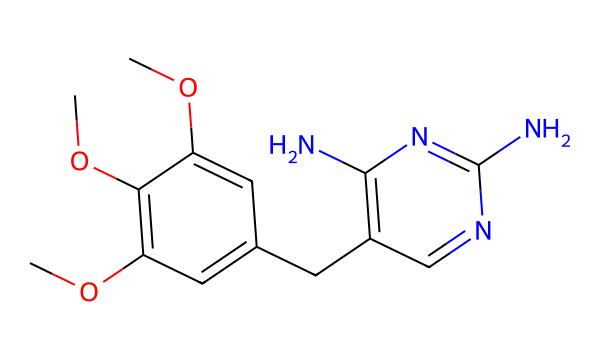

In [3]:
from IPython.display import SVG

tmp = Chem.MolFromSmiles(D.TMP_SMILES)
AllChem.Compute2DCoords(tmp)

# Plain structure: heteroatom colouring only, no highlight overlays.
drawer = rdMolDraw2D.MolDraw2DSVG(600, 360)
opts = drawer.drawOptions()
opts.bondLineWidth = 2
opts.additionalAtomLabelPadding = 0.08
rdMolDraw2D.PrepareAndDrawMolecule(drawer, tmp)
drawer.FinishDrawing()
svg = drawer.GetDrawingText()
(D.FIGURES / "fig0b_trimethoprim.svg").write_text(svg)

# Report the fragments by atom count rather than painting them on.
frags = {
    "diaminopyrimidine (warhead, binds Asp27)": "c1nc(N)nc(N)c1",
    "trimethoxyphenyl (hydrophobic)": "c1cc(OC)c(OC)c(OC)c1",
    "methylene bridge": "[cX3][CH2][cX3]",
}
for label, smarts in frags.items():
    match = tmp.GetSubstructMatch(Chem.MolFromSmarts(smarts))
    print(f"{label:44s} {len(match):2d} atoms")

print(f"\n{'rotatable branches':44s} "
      f"{D.n_rotatable(D.PREP / 'tmp_protonated.pdbqt'):2d}")
SVG(svg)

## Elastic network model

### What it is

An **elastic network model (ENM)** is the crudest useful physics model of a protein.
Throw away all chemistry. Keep one bead per alpha-carbon. Join every pair of beads
closer than a cutoff $r_c$ with an identical linear spring. Then ask what that
ball-and-spring object does near equilibrium.

It sounds far too simple to work, and it does work — the slow collective motions of
real proteins are largely dictated by the *shape* of the fold, not by chemical detail.

### Gaussian Network Model

The GNM assumes isotropic Gaussian fluctuations. The topology is captured by the
Kirchhoff (graph Laplacian) matrix $\boldsymbol{\Gamma}$:

$$
\Gamma_{ij} \;=\;
\begin{cases}
-1, & i \neq j \;\text{and}\; R_{ij} \le r_c \\[2pt]
0, & i \neq j \;\text{and}\; R_{ij} > r_c \\[2pt]
-\sum_{k \neq i} \Gamma_{ik}, & i = j
\end{cases}
$$

with potential energy for displacements $\Delta\mathbf{R}$

$$
V \;=\; \frac{\gamma}{2}\,\Delta\mathbf{R}^{\mathsf{T}} \boldsymbol{\Gamma} \, \Delta\mathbf{R}
$$

Equipartition then gives the mean-square fluctuation of residue $i$ directly from the
pseudo-inverse diagonal:

$$
\bigl\langle \Delta\mathbf{R}_i \cdot \Delta\mathbf{R}_i \bigr\rangle \;=\; \frac{3k_{\mathrm{B}}T}{\gamma}\,\bigl[\boldsymbol{\Gamma}^{-1}\bigr]_{ii}
$$

Decomposing over the eigenmodes $\boldsymbol{\Gamma}\mathbf{u}_k = \lambda_k \mathbf{u}_k$:

$$
\bigl[\boldsymbol{\Gamma}^{-1}\bigr]_{ii} \;=\; \sum_{k=2}^{N} \frac{1}{\lambda_k}\,[\mathbf{u}_k]_i^{2}
$$

The sum starts at $k = 2$ because $\lambda_1 = 0$ is the trivial translation mode.
Small $\lambda_k$ dominates, so **the slowest modes carry the largest motions** — which
is why only the first 20 are computed below.

### Anisotropic Network Model

The ANM keeps directionality, replacing the $N \times N$ Kirchhoff matrix with a
$3N \times 3N$ Hessian built from second derivatives of the same harmonic potential:

$$
\mathbf{H}_{ij} \;=\; -\frac{\gamma}{R_{ij}^{2}}
\begin{pmatrix}
\Delta x^2 & \Delta x \Delta y & \Delta x \Delta z \\
\Delta y \Delta x & \Delta y^2 & \Delta y \Delta z \\
\Delta z \Delta x & \Delta z \Delta y & \Delta z^2
\end{pmatrix}
$$

Now six eigenvalues vanish (three translations, three rotations), and each mode is an
actual 3D direction of motion rather than a magnitude.

### Why bother here

The ENM has no training data, no sequence information and no knowledge of AlphaFold.
If it independently flags the regions where AlphaFold's prediction deviates from the
crystal, that is a third line of evidence — mechanics agreeing with pLDDT and PAE.

**Caveat, stated up front:** an ENM describes the single conformation it is given.
`1RX2` is a closed, ligand-bound state, so anything pinned down by the folate or the
cofactor will look rigid regardless of its behaviour during catalysis.

In [4]:
from prody import ANM, GNM, calcSqFlucts, confProDy, parsePDB

confProDy(verbosity="none")

structure = parsePDB(str(D.RAW / "1RX2.pdb"))
calphas = structure.select("calpha and chain A")
resnums = calphas.getResnums()
print(f"alpha-carbons: {len(resnums)} (residues {resnums.min()}-{resnums.max()})")

gnm = GNM("DHFR GNM")
gnm.buildKirchhoff(calphas, cutoff=7.3)
gnm.calcModes(n_modes=20)

anm = ANM("DHFR ANM")
anm.buildHessian(calphas, cutoff=15.0)
anm.calcModes(n_modes=20)

gnm_flucts = pd.Series(calcSqFlucts(gnm), index=resnums, name="gnm")
anm_flucts = pd.Series(calcSqFlucts(anm), index=resnums, name="anm")
mode1 = pd.Series(np.abs(gnm[0].getEigvec()), index=resnums, name="mode1")

print(f"GNM modes: {gnm.numModes()},  ANM modes: {anm.numModes()}")

alpha-carbons: 159 (residues 1-159)
GNM modes: 20,  ANM modes: 20


In [5]:
# Bring in pLDDT and the crystal-vs-prediction deviation from notebook 01.
import warnings

from Bio.PDB import PDBParser, Superimposer
from Bio.PDB.PDBExceptions import PDBConstructionWarning

warnings.simplefilter("ignore", PDBConstructionWarning)
parser = PDBParser(QUIET=True)


def ca_map(path, chain_id=None):
    model = parser.get_structure("s", path)[0]
    ch = model[chain_id] if chain_id else next(iter(model))
    return {r.id[1]: r["CA"] for r in ch if r.id[0] == " " and "CA" in r}


af_pdb = D.RAW / "AF-P0ABQ4-F1-model_v6.pdb"
af_struct = parser.get_structure("af", af_pdb)
pred, crys = ca_map(af_pdb), ca_map(D.RAW / "1RX2.pdb", "A")
common = sorted(set(pred) & set(crys))

sup = Superimposer()
sup.set_atoms([crys[i] for i in common], [pred[i] for i in common])
sup.apply(list(af_struct.get_atoms()))
fitted = {r.id[1]: r["CA"] for r in next(iter(af_struct[0])) if r.id[0] == " "}

deviation = pd.Series(
    {i: float(np.linalg.norm(fitted[i].coord - crys[i].coord)) for i in common},
    name="deviation")

plddt = pd.Series(
    {r.id[1]: sum(a.bfactor for a in r) / len(list(r))
     for r in next(iter(parser.get_structure("af2", af_pdb)[0])) if r.id[0] == " "},
    name="plddt")

panel = pd.concat([gnm_flucts, anm_flucts, deviation, plddt], axis=1).dropna()
panel.head()

,gnm,anm,deviation,plddt
1,0.075987,0.019467,0.306153,97.69
2,0.052869,0.009935,0.120177,98.75
3,0.042480,0.007584,0.104722,98.88
4,0.030615,0.005645,0.049199,98.81
5,0.038581,0.005662,0.111571,98.81


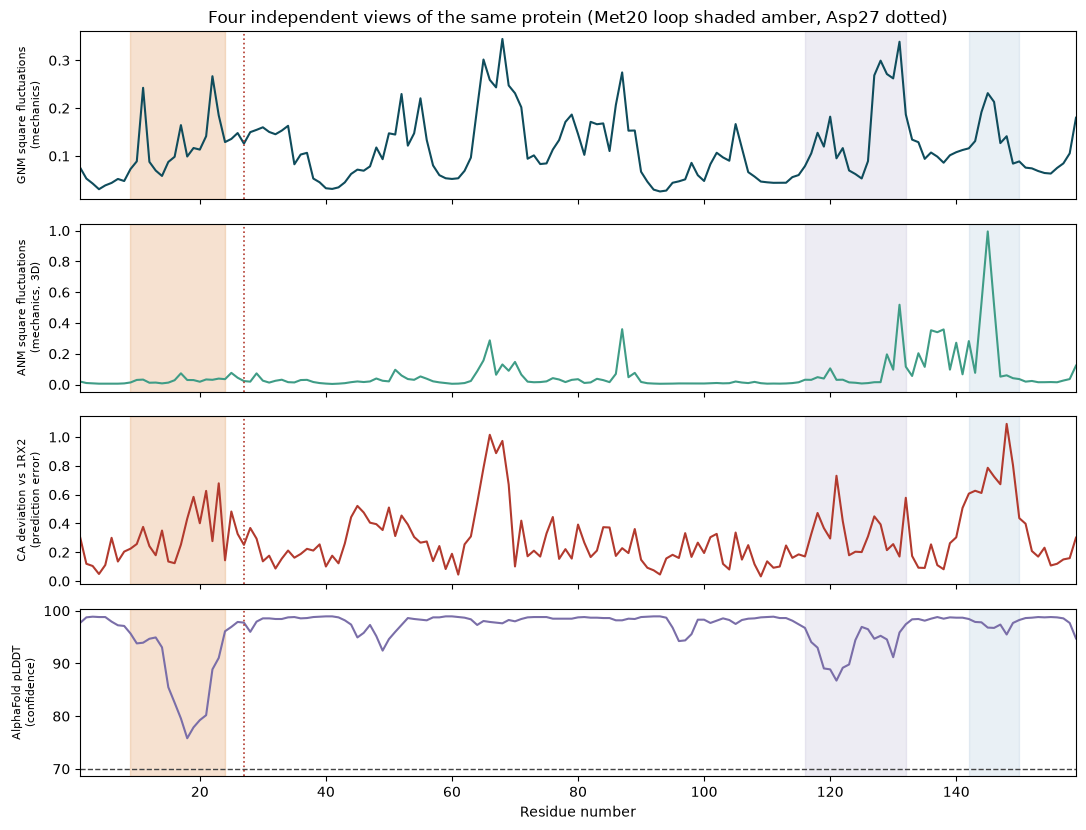

In [6]:
fig, axes = plt.subplots(4, 1, figsize=(11, 8.4), sharex=True)

series = [
    ("GNM square fluctuations\n(mechanics)", panel.gnm, TEAL, None),
    ("ANM square fluctuations\n(mechanics, 3D)", panel.anm, "#3f9c86", None),
    ("CA deviation vs 1RX2\n(prediction error)", panel.deviation, RED, None),
    ("AlphaFold pLDDT\n(confidence)", panel.plddt, "#7a6ea8", 70),
]

for ax, (label, s, colour, hline) in zip(axes, series):
    ax.axvspan(*MET20_LOOP, color=AMBER, alpha=0.22)
    ax.axvspan(*FG_LOOP, color="#7a6ea8", alpha=0.13)
    ax.axvspan(*GH_LOOP, color="#5a8fb8", alpha=0.13)
    ax.plot(s.index, s.values, lw=1.5, color=colour)
    if hline is not None:
        ax.axhline(hline, ls="--", lw=1.0, color="#444")
    ax.axvline(ASP27, ls=":", lw=1.2, color=RED)
    ax.set_ylabel(label, fontsize=8)

axes[0].set_title("Four independent views of the same protein "
                  "(Met20 loop shaded amber, Asp27 dotted)")
axes[-1].set_xlabel("Residue number")
axes[-1].set_xlim(panel.index.min(), panel.index.max())
fig.tight_layout()
fig.savefig(D.FIGURES / "fig5_enm_vs_confidence.png", dpi=300, bbox_inches="tight")
plt.show()

In [7]:
def region_row(name, lo, hi):
    block, rest = panel.loc[lo:hi], panel.drop(panel.loc[lo:hi].index)
    return {
        "region": name, "residues": f"{lo}-{hi}",
        "GNM_vs_rest": round(block.gnm.mean() / rest.gnm.mean(), 2),
        "ANM_vs_rest": round(block.anm.mean() / rest.anm.mean(), 2),
        "mean_deviation_A": round(block.deviation.mean(), 2),
        "mean_pLDDT": round(block.plddt.mean(), 1),
    }


regions = pd.DataFrame([
    region_row("Met20 loop", *MET20_LOOP),
    region_row("F-G loop", *FG_LOOP),
    region_row("G-H loop", *GH_LOOP),
    region_row("active site", 25, 32),
]).sort_values("GNM_vs_rest", ascending=False)

regions.to_csv(D.RESULTS / "flexibility.csv", index=False)
print("Mobility relative to the rest of the chain (>1 means more mobile)\n")
regions

Mobility relative to the rest of the chain (>1 means more mobile)



,region,residues,GNM_vs_rest,ANM_vs_rest,mean_deviation_A,mean_pLDDT
1,F-G loop,116-132,1.44,1.31,0.34,93.2
2,G-H loop,142-150,1.27,6.04,0.71,97.4
3,active site,25-32,1.26,0.59,0.27,97.8
0,Met20 loop,9-24,1.09,0.42,0.33,87.7


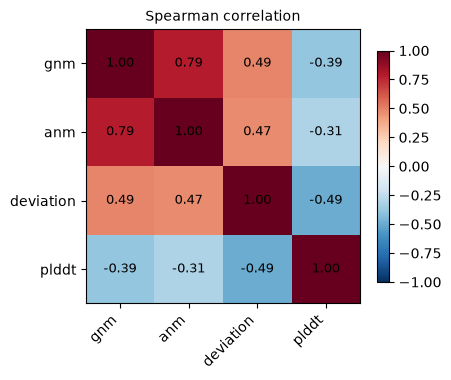

GNM mobility vs prediction error : rho = +0.491
pLDDT vs prediction error        : rho = -0.495
GNM mobility vs pLDDT            : rho = -0.388


In [8]:
corr = panel.corr(method="spearman").round(3)

fig, ax = plt.subplots(figsize=(4.6, 3.9))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)), corr.index)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9)
ax.set_title("Spearman correlation", fontsize=10)
fig.colorbar(im, ax=ax, shrink=0.8)
fig.tight_layout()
fig.savefig(D.FIGURES / "fig5b_correlation.png", dpi=300, bbox_inches="tight")
plt.show()

print(f"GNM mobility vs prediction error : rho = {corr.loc['gnm', 'deviation']:+.3f}")
print(f"pLDDT vs prediction error        : rho = {corr.loc['plddt', 'deviation']:+.3f}")
print(f"GNM mobility vs pLDDT            : rho = {corr.loc['gnm', 'plddt']:+.3f}")

## 3D - the redocked pose against the crystal pose

Interactive. Teal cartoon is the receptor, grey sticks the NADPH cofactor, **amber**
the docked trimethoprim and **green** the crystal pose. If the gate passed they should
be nearly superimposed.

In [9]:
import py3Dmol
from meeko import PDBQTMolecule, RDKitMolCreate


def top_pose_block(pdbqt_path):
    pm = PDBQTMolecule.from_file(str(pdbqt_path), skip_typing=True)
    mol = RDKitMolCreate.from_pdbqt_mol(pm)[0]
    return Chem.MolToPDBBlock(mol, confId=0)


receptor_pdb = (D.PREP / "2w9g_receptor_raw.pdb").read_text()
docked = top_pose_block(D.RESULTS / "redock_2w9g_protonated_s1.pdbqt")
crystal = (D.PREP / "2w9g_TOP_xtal.pdb").read_text()

view = py3Dmol.view(width=820, height=520)
view.addModel(receptor_pdb, "pdb")
view.setStyle({"model": 0}, {"cartoon": {"color": TEAL, "opacity": 0.72}})
view.addStyle({"model": 0, "resn": "NDP"},
              {"stick": {"colorscheme": "greyCarbon", "radius": 0.17}})
view.addStyle({"model": 0, "resi": "27"},
              {"stick": {"colorscheme": "redCarbon", "radius": 0.2}})

view.addModel(docked, "pdb")
view.setStyle({"model": 1}, {"stick": {"colorscheme": "orangeCarbon", "radius": 0.22}})

view.addModel(crystal, "pdb")
view.setStyle({"model": 2}, {"stick": {"colorscheme": "greenCarbon", "radius": 0.22}})

view.zoomTo({"model": 2})
view.zoom(0.7)
view.show()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

## 3D - AlphaFold model coloured by pLDDT

Standard AlphaFold colours: dark blue very high, light blue confident, yellow low,
orange very low.

In [10]:
view = py3Dmol.view(width=820, height=520)
view.addModel(af_pdb.read_text(), "pdb")
view.setStyle({"cartoon": {
    "colorscheme": {
        "prop": "b",
        "gradient": "linear",
        "colors": ["#ff7d45", "#ffdb13", "#65cbf3", "#0053d6"],
        "min": 50, "max": 100,
    }
}})
lo, hi = MET20_LOOP
view.addStyle({"resi": list(range(lo, hi + 1))},
              {"cartoon": {"color": AMBER, "thickness": 1.0}})
view.addStyle({"resi": str(ASP27)},
              {"stick": {"colorscheme": "redCarbon", "radius": 0.25}})
view.zoomTo()
view.show()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

## What the numbers say

In [11]:
met20 = regions[regions.region == "Met20 loop"].iloc[0]
most_mobile = regions.iloc[0]
rho_gnm = corr.loc["gnm", "deviation"]
rho_plddt = corr.loc["plddt", "deviation"]

print(f"Most mobile region by GNM : {most_mobile['region']} "
      f"({most_mobile['GNM_vs_rest']}x the rest of the chain)")
print(f"Met20 loop GNM mobility   : {met20['GNM_vs_rest']}x")
print(f"Met20 loop mean pLDDT     : {met20['mean_pLDDT']}")
print(f"Met20 loop mean deviation : {met20['mean_deviation_A']} A")
print()

print("Reading this honestly:")
print()

if most_mobile["region"] != "Met20 loop":
    print(f"  The ENM's top region is the {most_mobile['region']}, not the Met20 loop.")
    print(f"  Met20 comes out only {met20['GNM_vs_rest']}x - barely above average.")
    print()
    print("  That is expected, and it is the useful lesson: 1RX2 is a CLOSED,")
    print("  ligand-bound structure. The Met20 loop is pinned down by the folate and")
    print("  the cofactor, so a spring model built on that geometry sees it as held in")
    print("  place. The ENM describes the conformation you hand it, not the protein's")
    print("  full repertoire. The loop's famous mobility is a property of the catalytic")
    print("  cycle, not of this single snapshot.")
else:
    print(f"  The ENM independently flags the Met20 loop ({met20['GNM_vs_rest']}x).")

print()
print(f"  Across the whole chain, GNM mobility tracks prediction error at rho = {rho_gnm:+.2f},")
print(f"  and pLDDT tracks it at rho = {rho_plddt:+.2f}. A spring model that has never seen")
print("  a training set anticipates where AlphaFold struggles about as well as")
print("  AlphaFold's own confidence does - both point at mobile regions.")
print()
print("  Caveat: all deviations here are small (max "
      f"{panel.deviation.max():.2f} A), so these correlations describe")
print("  the texture of a very good prediction, not a rescue of a bad one.")

print()
print("figures written:")
for f in sorted(D.FIGURES.glob("*")):
    if f.name != ".gitkeep":
        print(f"   {f.name:34s} {f.stat().st_size // 1024:4d} KB")

Most mobile region by GNM : F-G loop (1.44x the rest of the chain)
Met20 loop GNM mobility   : 1.09x
Met20 loop mean pLDDT     : 87.7
Met20 loop mean deviation : 0.33 A

Reading this honestly:

  The ENM's top region is the F-G loop, not the Met20 loop.
  Met20 comes out only 1.09x - barely above average.

  That is expected, and it is the useful lesson: 1RX2 is a CLOSED,
  ligand-bound structure. The Met20 loop is pinned down by the folate and
  the cofactor, so a spring model built on that geometry sees it as held in
  place. The ENM describes the conformation you hand it, not the protein's
  full repertoire. The loop's famous mobility is a property of the catalytic
  cycle, not of this single snapshot.

  Across the whole chain, GNM mobility tracks prediction error at rho = +0.49,
  and pLDDT tracks it at rho = -0.49. A spring model that has never seen
  a training set anticipates where AlphaFold struggles about as well as
  AlphaFold's own confidence does - both point at mobile reg